# Amine BOURAMTANE

# TP — Seuillage d’images et prédiction du seuil par Machine Learning

**Objectif :** générer des images synthétiques en niveaux de gris, calculer le seuil d’Otsu, puis apprendre à prédire le seuil cible avec une régression linéaire et un Random Forest.

> **Méthodologie du TP :** le seuil cible \(T^*\) est défini à partir des intensités du fond et de l’objet connues pendant la génération. Cette expérience étudie une règle sur un jeu synthétique ; elle ne prouve pas que le Machine Learning surpasse Otsu sur des images réelles.

## 0. Imports et reproductibilité

In [1]:
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

## Partie A — Génération des images et construction du dataset

Chaque image contient un fond et une forme (disque ou rectangle) d’intensité différente. Les intensités et la taille varient, avec un bruit faible. Pour chaque image, on enregistre la moyenne, l’écart-type, la proportion de pixels ≤ 127, le seuil d’Otsu et le seuil cible \(T^*\).

Ici, le seuil cible est le milieu entre les intensités de fond et de l’objet, connues lors de la génération.

In [ ]:
def make_sample(size=128):
    # Intensités séparées et dans [0, 255], avec un contraste visible
    background = int(rng.integers(20, 111))
    object_intensity = int(rng.integers(background + 35, min(background + 120, 256)))
    mask = np.zeros((size, size), dtype=np.uint8)

    # Forme et taille variables
    s = int(rng.integers(12, 36))
    x = int(rng.integers(s, size - s))
    y = int(rng.integers(s, size - s))
    if rng.random() < 0.5:
        cv2.circle(mask, (x, y), s, 1, -1)
    else:
        x1, y1 = max(0, x - s), max(0, y - s)
        x2, y2 = min(size - 1, x + s), min(size - 1, y + s)
        cv2.rectangle(mask, (x1, y1), (x2, y2), 1, -1)

    image = np.where(mask == 1, object_intensity, background).astype(np.float32)
    image += rng.normal(0, 4, image.shape)  # faible bruit
    image = np.clip(image, 0, 255).astype(np.uint8)

    # Seuil cible issu des intensités connues à la génération
    target_threshold = (background + object_intensity) / 2
    return image, mask, background, object_intensity, target_threshold

def extract_features(image):
    x = image.astype(np.float64).ravel()
    otsu, _ = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return [x.mean(), x.std(), np.mean(x <= 127), otsu]

FEATURES = ["moyenne", "écart-type", "proportion_pixels_<=127", "seuil_Otsu"]

N = 1000  
samples = [make_sample() for _ in range(N)]
images = [s[0] for s in samples]
masks = [s[1] for s in samples]
backgrounds = np.array([s[2] for s in samples])
object_intensities = np.array([s[3] for s in samples])
y = np.array([s[4] for s in samples], dtype=float)
X = np.array([extract_features(img) for img in images], dtype=float)

dataset = pd.DataFrame(X, columns=FEATURES)
dataset["seuil_cible_T*"] = y
dataset.head()

,moyenne,écart-type,proportion_pixels_<=127,seuil_Otsu,seuil_cible_T*
0,45.930237,39.003873,0.909912,44.0,78.0
1,101.714661,14.980743,0.925232,112.0,125.5
2,79.265259,10.132018,0.985779,98.0,102.5
3,45.872498,10.222383,1.000000,60.0,63.5
4,50.039795,17.046832,1.000000,60.0,72.5


In [3]:
print(f"Nombre d’images : {N}")
print(f"Nombre de caractéristiques : {X.shape[1]}")
print(f"Plage du seuil cible T* : {y.min():.1f} à {y.max():.1f}")
print(f"Fond moyen : {backgrounds.mean():.1f} | Objet moyen : {object_intensities.mean():.1f}")

Nombre d’images : 1000
Nombre de caractéristiques : 4
Plage du seuil cible T* : 40.0 à 167.0
Fond moyen : 66.0 | Objet moyen : 142.4


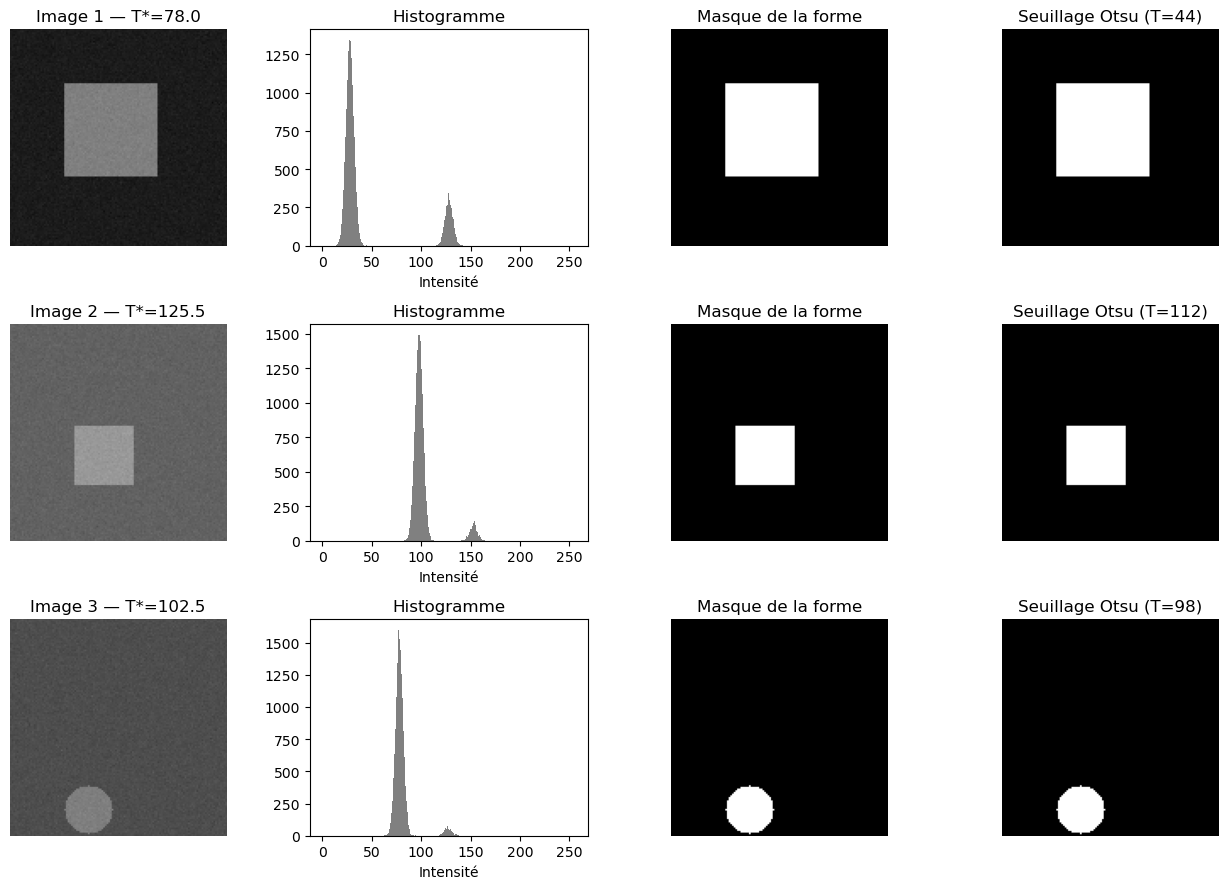

In [4]:
# Afficher quelques images et leurs histogrammes
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for row, k in enumerate([0, 1, 2]):
    axes[row, 0].imshow(images[k], cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Image {k+1} — T*={y[k]:.1f}")
    axes[row, 0].axis("off")
    axes[row, 1].hist(images[k].ravel(), bins=256, range=(0, 256), color="gray")
    axes[row, 1].set_title("Histogramme")
    axes[row, 1].set_xlabel("Intensité")
    axes[row, 2].imshow(masks[k], cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Masque de la forme")
    axes[row, 2].axis("off")
    otsu, _ = cv2.threshold(images[k], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    axes[row, 3].imshow(images[k] > otsu, cmap="gray")
    axes[row, 3].set_title(f"Seuillage Otsu (T={otsu:.0f})")
    axes[row, 3].axis("off")
plt.tight_layout()
plt.show()

### Questions A — Réponses

1. **Pourquoi plusieurs images ?** Elles permettent au modèle d’apprendre des relations variées et d’être évalué sur des exemples qu’il n’a pas vus.
2. **Caractéristique et cible :** une caractéristique est une mesure fournie en entrée dans \(X\) ; la cible \(y\) est la valeur que le modèle doit apprendre à prédire, ici \(T^*\).
3. **Limites du dataset synthétique :** il ne couvre pas toute la diversité des images réelles (éclairage complexe, textures, ombres, formes et bruit variés).

## Partie B — Calculer le seuil d’Otsu

OpenCV calcule automatiquement le seuil avec `THRESH_BINARY + THRESH_OTSU`. Le seuil fourni en argument est mis à `0` car Otsu choisit lui-même le seuil à partir de l’histogramme.

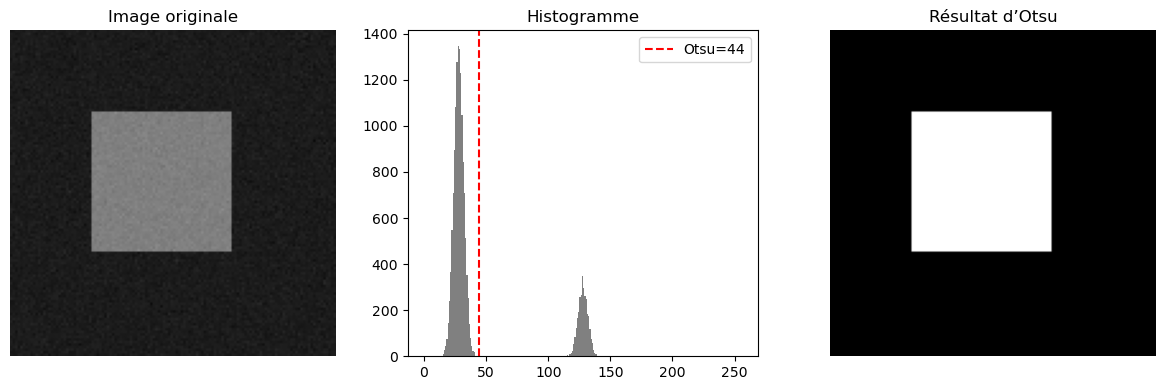

T* cible = 78.0 | seuil Otsu = 44.0


In [5]:
def apply_otsu(image):
    threshold, binary = cv2.threshold(
        image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    return threshold, binary

k = 0
otsu_threshold, binary_otsu = apply_otsu(images[k])
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(images[k], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Image originale")
axes[1].hist(images[k].ravel(), bins=256, range=(0, 256), color="gray")
axes[1].axvline(otsu_threshold, color="red", linestyle="--", label=f"Otsu={otsu_threshold:.0f}")
axes[1].set_title("Histogramme"); axes[1].legend()
axes[2].imshow(binary_otsu, cmap="gray")
axes[2].set_title("Résultat d’Otsu")
for ax in axes:
    if ax is not axes[1]: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"T* cible = {y[k]:.1f} | seuil Otsu = {otsu_threshold:.1f}")

### Questions B — Réponses

1. Le seuil `0` est une valeur de départ ignorée lorsque `THRESH_OTSU` est activé : OpenCV estime le seuil à partir de l’histogramme.
2. **Non.** Otsu optimise un critère statistique de séparation de l’histogramme, alors que \(T^*\) est défini ici par les intensités connues lors de la génération.
3. Un seuil global peut être imparfait si l’éclairage varie selon la position, si les classes se chevauchent en intensité, ou si l’image contient plusieurs régions/objets aux intensités différentes.

## Partie C — Entraîner les modèles supervisés

Séparation demandée : **75 % apprentissage / 25 % test**, avec `random_state=42`. On entraîne une régression linéaire et un `RandomForestRegressor` de 100 arbres. Les performances sont évaluées par MAE, RMSE et \(R^2\).

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

modele_lr = LinearRegression()
modele_lr.fit(X_train, y_train)

modele_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modele_rf.fit(X_train, y_train)

pred_lr = np.clip(modele_lr.predict(X_test), 0, 255)
pred_rf = np.clip(modele_rf.predict(X_test), 0, 255)
pred_otsu = X_test[:, FEATURES.index("seuil_Otsu")]

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

comparaison_modeles = pd.DataFrame({
    "Régression linéaire": regression_metrics(y_test, pred_lr),
    "Random Forest": regression_metrics(y_test, pred_rf),
    "Otsu (référence)": regression_metrics(y_test, pred_otsu)
}).T
comparaison_modeles.round(3)

,MAE,RMSE,R²
Régression linéaire,4.455,5.783,0.959
Random Forest,3.488,4.730,0.973
Otsu (référence),24.072,26.930,0.117


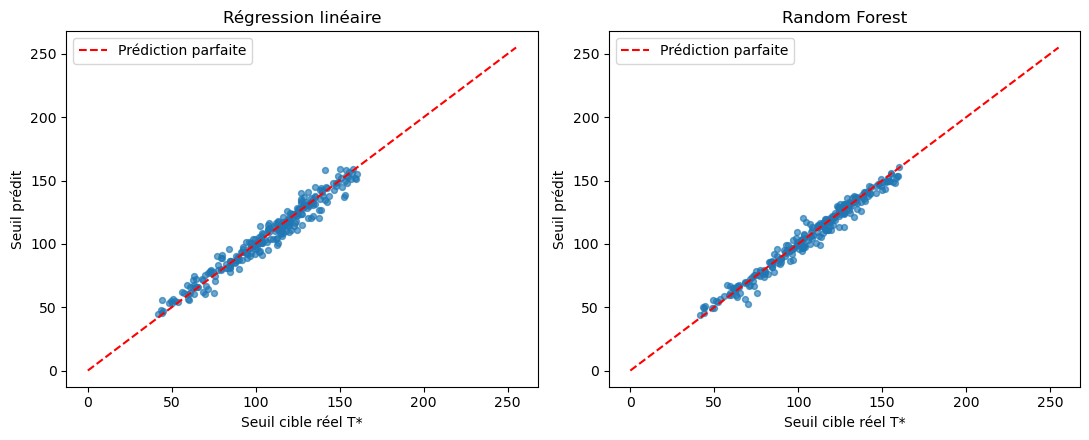

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [
    ("Régression linéaire", pred_lr),
    ("Random Forest", pred_rf)
]):
    ax.scatter(y_test, pred, alpha=0.65, s=18)
    ax.plot([0, 255], [0, 255], "r--", label="Prédiction parfaite")
    ax.set_xlabel("Seuil cible réel T*")
    ax.set_ylabel("Seuil prédit")
    ax.set_title(name)
    ax.legend()
plt.tight_layout(); plt.show()

### Questions C — Réponses

1. Le modèle ayant la plus petite MAE est celui dont la valeur MAE est la plus basse dans le tableau précédent ; le résultat dépend des données générées et doit être constaté après exécution.
2. La séparation train/test estime la capacité de généralisation sur des images non utilisées pour ajuster les modèles.
3. Non. Une meilleure performance sur ce jeu synthétique ne garantit pas de meilleures performances sur d’autres distributions ou sur des images réelles.

## Partie D — Comparaison sur les mêmes images de test

On compare \(T^*\), Otsu, la régression linéaire et Random Forest. Pour chaque méthode, on calcule l’erreur absolue par rapport à \(T^*\) et on affiche au moins trois exemples avec leurs résultats binaires.

In [8]:
# Tableau de seuils et erreurs absolues sur les images de test
comparaison_seuils = pd.DataFrame({
    "T* cible": y_test,
    "Seuil Otsu": pred_otsu,
    "Seuil régression linéaire": pred_lr,
    "Seuil Random Forest": pred_rf
})
for col in ["Seuil Otsu", "Seuil régression linéaire", "Seuil Random Forest"]:
    comparaison_seuils["Erreur absolue — " + col] = np.abs(comparaison_seuils[col] - comparaison_seuils["T* cible"])
comparaison_seuils.head(10).round(2)

,T* cible,Seuil Otsu,Seuil régression linéaire,Seuil Random Forest,Erreur absolue — Seuil Otsu,Erreur absolue — Seuil régression linéaire,Erreur absolue — Seuil Random Forest
0,118.5,91.0,125.95,116.85,27.5,7.45,1.65
1,129.0,107.0,136.67,127.14,22.0,7.67,1.86
2,108.0,103.0,116.63,113.08,5.0,8.63,5.08
3,141.5,97.0,134.93,137.99,44.5,6.57,3.51
4,142.5,110.0,132.79,140.50,32.5,9.71,2.00
5,146.5,106.0,142.67,139.84,40.5,3.83,6.66
6,59.0,39.0,67.27,60.00,20.0,8.27,0.99
7,88.0,45.0,87.00,84.78,43.0,1.00,3.22
8,92.0,89.0,93.39,90.67,3.0,1.39,1.33
9,124.0,99.0,124.18,125.12,25.0,0.18,1.12


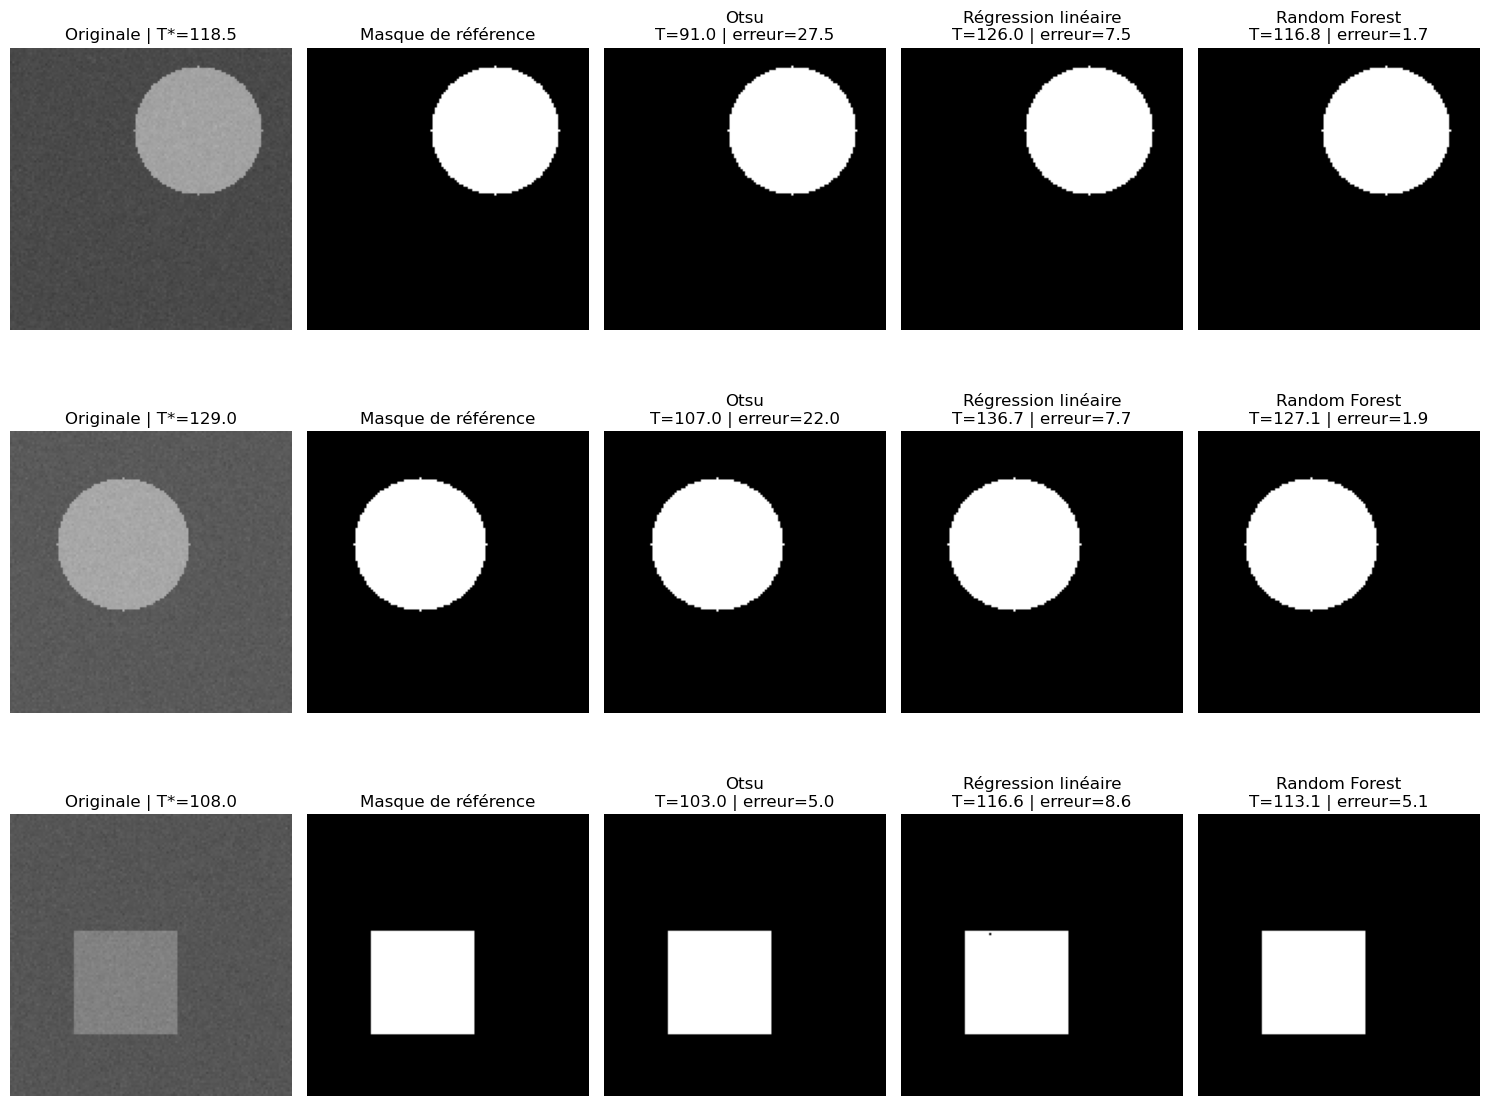

In [9]:
# Visualisation détaillée de trois images de test
n_examples = min(3, len(y_test))
fig, axes = plt.subplots(n_examples, 5, figsize=(15, 4 * n_examples))
if n_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for row in range(n_examples):
    image_idx = np.where(np.isclose(X, X_test[row]).all(axis=1))[0]
    # Indices test explicites pour éviter toute ambiguïté liée aux caractéristiques identiques
    test_indices = np.arange(N)
    _, test_indices = train_test_split(test_indices, test_size=0.25, random_state=42)
    img = images[test_indices[row]]
    target = y_test[row]
    thresholds = [
        ("Masque cible", None),
        ("Otsu", pred_otsu[row]),
        ("Régression linéaire", pred_lr[row]),
        ("Random Forest", pred_rf[row])
    ]
    axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Originale | T*={target:.1f}")
    axes[row, 0].axis("off")
    axes[row, 1].imshow(masks[test_indices[row]], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Masque de référence")
    axes[row, 1].axis("off")
    for col, (name, threshold) in enumerate(thresholds[1:], start=2):
        axes[row, col].imshow(img > threshold, cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"{name}\nT={threshold:.1f} | erreur={abs(threshold-target):.1f}")
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

In [10]:
# Tableau de synthèse pour trois exemples : seuil, erreur absolue et commentaire visuel
test_indices = np.arange(N)
_, test_indices = train_test_split(test_indices, test_size=0.25, random_state=42)
rows = []
for j in range(min(3, len(y_test))):
    target = y_test[j]
    for name, threshold in [
        ("Seuil cible T*", target),
        ("Otsu", pred_otsu[j]),
        ("Régression linéaire", pred_lr[j]),
        ("Random Forest", pred_rf[j])
    ]:
        err = abs(threshold - target)
        comment = ("Référence utilisée pour définir le seuil cible" if name == "Seuil cible T*" else
                   "Segmentation proche du seuil cible" if err <= 5 else
                   "Écart notable au seuil cible ; vérifier visuellement la segmentation")
        rows.append({
            "Image test": j + 1,
            "Méthode": name,
            "Seuil obtenu": round(float(threshold), 2),
            "Erreur absolue par rapport à T*": round(float(err), 2),
            "Commentaire": comment
        })
tableau_synthese = pd.DataFrame(rows)
tableau_synthese

,Image test,Méthode,Seuil obtenu,Erreur absolue par rapport à T*,Commentaire
0,1,Seuil cible T*,118.50,0.00,Référence utilisée pour définir le seuil cible
1,1,Otsu,91.00,27.50,Écart notable au seuil cible ; vérifier visuel...
2,1,Régression linéaire,125.95,7.45,Écart notable au seuil cible ; vérifier visuel...
3,1,Random Forest,116.85,1.65,Segmentation proche du seuil cible
4,2,Seuil cible T*,129.00,0.00,Référence utilisée pour définir le seuil cible
5,2,Otsu,107.00,22.00,Écart notable au seuil cible ; vérifier visuel...
6,2,Régression linéaire,136.67,7.67,Écart notable au seuil cible ; vérifier visuel...
7,2,Random Forest,127.14,1.86,Segmentation proche du seuil cible
8,3,Seuil cible T*,108.00,0.00,Référence utilisée pour définir le seuil cible
9,3,Otsu,103.00,5.00,Segmentation proche du seuil cible


### Questions D — Réponses

1. Oui, une régression peut prédire une valeur hors de \([0,255]\). On peut borner la prédiction avec `np.clip(prediction, 0, 255)`, comme dans ce notebook.
2. Une petite erreur sur le seuil ne garantit pas la meilleure segmentation : la qualité dépend aussi du chevauchement des intensités, du bruit, de l’éclairage et de la distribution des pixels.
3. Les images synthétiques restent simples et contrôlées ; elles ne représentent pas toute la diversité des textures, ombres, éclairages et objets du monde réel.
4. Il faudrait un jeu d’images réelles représentatif, des masques de référence annotés, un protocole de séparation indépendant et une évaluation sur plusieurs scènes/modalités.